# PRIM on Distance Ratio — bcas = 0.07

At peak casualty rate, find the distance box that separates
"pooling helps" from "pooling does not help" for each policy.
Instantaneous wave (1 min, 1/day), loose distances (same_bn 10-40, inter_bn 15-70).

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

RESULTS_PATH = _root / "data_cluster" / "resource_grid" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
df = df[df["n_amb_r1_to_ccp"] == 2].reset_index(drop=True)
print(f"Loaded {len(df)} runs (filtered n_amb==2)")

# Filter to bcas = 0.07 only
df = df[df["bcas_rate"] == 0.07].reset_index(drop=True)
print(f"Filtered to bcas=0.07: {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]

stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
amb   = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
fac   = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
both  = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)

assert (stove["scenario"].values == amb["scenario"].values).all()
assert (stove["scenario"].values == fac["scenario"].values).all()
assert (stove["scenario"].values == both["scenario"].values).all()
print(f"Matched scenarios: {len(stove)}")

# Add distance ratio
x = stove[UNCERTAINTIES].astype(float).copy()
x["distance_ratio"] = x["ccp_r1_same_bn_min"] / x["ccp_r1_inter_bn_min"]
print(f"Distance ratio: min={x['distance_ratio'].min():.3f}, max={x['distance_ratio'].max():.3f}")

## Summary — Benefit distribution at bcas=0.07

In [2]:
comparisons = [
    ("Amb only",  amb),
    ("Fac only",  fac),
    ("Both",      both),
]

for label, policy_df in comparisons:
    delta = stove["death_rate_T1_BCAS"].values - policy_df["death_rate_T1_BCAS"].values
    n_help = (delta > 0.01).sum()
    n_hurt = (delta < -0.01).sum()
    n_neutral = len(delta) - n_help - n_hurt
    print(f"{label:12s}  helps: {n_help:5d} ({n_help/len(delta):5.1%})  hurts: {n_hurt:5d} ({n_hurt/len(delta):5.1%})  neutral: {n_neutral:5d} ({n_neutral/len(delta):5.1%})  median benefit: {np.median(delta):.4f}")

Amb only      helps:  1205 (60.2%)  hurts:   441 (22.1%)  neutral:   354 (17.7%)  median benefit: 0.0588
Fac only      helps:     0 ( 0.0%)  hurts:     0 ( 0.0%)  neutral:  2000 (100.0%)  median benefit: 0.0000
Both          helps:  1547 (77.3%)  hurts:   216 (10.8%)  neutral:   237 (11.8%)  median benefit: 0.1176


## PRIM — Ambulance pooling: where does it NOT help?

Amb pooling does NOT help: 795 / 2000 (39.8%)



Peeling trajectory (28 steps):
    coverage  density  mass  res_dim
0      1.000    0.398 1.000        0
1      1.000    0.425 0.936        1
2      1.000    0.456 0.871        1
3      1.000    0.493 0.806        1
4      0.989    0.515 0.762        2
5      0.980    0.540 0.721        2
6      0.960    0.575 0.664        2
7      0.940    0.600 0.623        2
8      0.914    0.622 0.584        2
9      0.886    0.646 0.544        2
10     0.857    0.672 0.506        2
11     0.842    0.695 0.481        3
12     0.826    0.724 0.454        3
13     0.797    0.735 0.431        3
14     0.771    0.762 0.402        3
15     0.737    0.786 0.373        3
16     0.704    0.809 0.346        3
17     0.678    0.844 0.320        3
18     0.644    0.865 0.296        3
19     0.609    0.900 0.269        3
20     0.582    0.911 0.254        3
21     0.527    0.929 0.226        3
22     0.502    0.955 0.209        3
23     0.481    0.965 0.198        3
24     0.455    0.973 0.186        3
25    

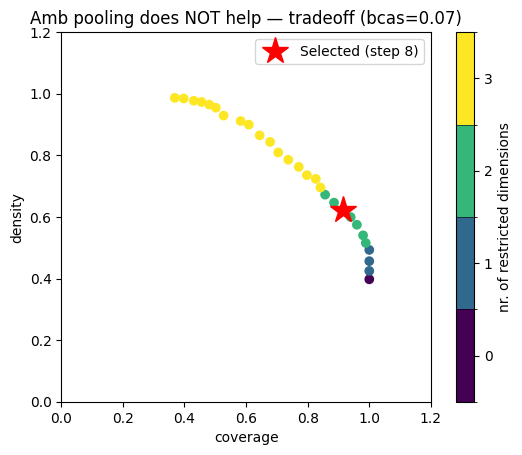


Selected step 8:
coverage       0.914465
density        0.622432
id             8.000000
k            727.000000
mass           0.584000
mean           0.622432
n           1168.000000
res_dim        2.000000
Name: 8, dtype: float64

                    box 8                             
                      min   max      qp value qp value
ccp_r1_same_bn_min   17.5  40.0  6.230684e-25      NaN
ccp_r1_inter_bn_min  26.5  70.0  9.755852e-12      NaN



In [3]:
delta_amb = stove["death_rate_T1_BCAS"].values - amb["death_rate_T1_BCAS"].values
y_amb_no_help = delta_amb <= 0.01
print(f"Amb pooling does NOT help: {y_amb_no_help.sum()} / {len(y_amb_no_help)} ({y_amb_no_help.mean():.1%})")

if y_amb_no_help.sum() >= 10:
    p_amb = prim.Prim(x, y_amb_no_help, threshold=0.5)
    box_amb = p_amb.find_box()
    
    traj = box_amb.peeling_trajectory
    print(f"\nPeeling trajectory ({len(traj)} steps):")
    print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))
    
    good = traj[(traj["density"] > 0.60) & (traj["coverage"] > 0.3)]
    if len(good) > 0:
        best_idx = int(good.index[0])
    else:
        good = traj[traj["density"] > 0.40]
        best_idx = int(good.index[0]) if len(good) > 0 else int(len(traj) - 1)
    
    box_amb.select(best_idx)
    box_amb.show_tradeoff()
    sel = traj.iloc[best_idx]
    plt.plot(sel["coverage"], sel["density"], "r*", markersize=20, zorder=5, label=f"Selected (step {best_idx})")
    plt.legend()
    plt.title("Amb pooling does NOT help — tradeoff (bcas=0.07)")
    plt.show()
    
    print(f"\nSelected step {best_idx}:")
    box_amb.inspect(best_idx)
else:
    print("Too few cases for PRIM.")

## PRIM — Facility pooling: where does it NOT help?

In [4]:
delta_fac = stove["death_rate_T1_BCAS"].values - fac["death_rate_T1_BCAS"].values
y_fac_no_help = delta_fac <= 0.01
print(f"Fac pooling does NOT help: {y_fac_no_help.sum()} / {len(y_fac_no_help)} ({y_fac_no_help.mean():.1%})")

if y_fac_no_help.sum() >= 10 and y_fac_no_help.mean() < 0.95:
    p_fac = prim.Prim(x, y_fac_no_help, threshold=0.5)
    box_fac = p_fac.find_box()
    
    traj = box_fac.peeling_trajectory
    print(f"\nPeeling trajectory ({len(traj)} steps):")
    print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))
    
    good = traj[(traj["density"] > 0.98) & (traj["coverage"] > 0.3)]
    if len(good) > 0:
        best_idx = int(good.index[0])
    else:
        good = traj[traj["density"] > 0.95]
        best_idx = int(good.index[0]) if len(good) > 0 else int(len(traj) - 1)
    
    box_fac.select(best_idx)
    box_fac.show_tradeoff()
    sel = traj.iloc[best_idx]
    plt.plot(sel["coverage"], sel["density"], "r*", markersize=20, zorder=5, label=f"Selected (step {best_idx})")
    plt.legend()
    plt.title("Fac pooling does NOT help — tradeoff (bcas=0.07)")
    plt.show()
    
    print(f"\nSelected step {best_idx}:")
    box_fac.inspect(best_idx)
else:
    if y_fac_no_help.mean() >= 0.95:
        print(f"Fac pooling almost never helps at bcas=0.07 ({y_fac_no_help.mean():.1%} no help). No PRIM needed.")
    else:
        print("Too few cases for PRIM.")

Fac pooling does NOT help: 2000 / 2000 (100.0%)
Fac pooling almost never helps at bcas=0.07 (100.0% no help). No PRIM needed.


## PRIM — Both pooling: where does it NOT help?

Both pooling does NOT help: 453 / 2000 (22.7%)



Peeling trajectory (30 steps):
    coverage  density  mass  res_dim
0      1.000    0.227 1.000        0
1      1.000    0.242 0.936        1
2      1.000    0.256 0.884        2
3      0.998    0.275 0.822        2
4      0.998    0.296 0.762        2
5      0.996    0.311 0.724        3
6      0.989    0.338 0.662        3
7      0.982    0.354 0.628        3
8      0.980    0.374 0.594        3
9      0.969    0.389 0.564        3
10     0.938    0.404 0.526        3
11     0.912    0.414 0.498        3
12     0.854    0.415 0.466        3
13     0.812    0.418 0.440        3
14     0.790    0.428 0.418        3
15     0.770    0.440 0.397        3
16     0.755    0.458 0.373        3
17     0.751    0.487 0.349        3
18     0.737    0.515 0.325        3
19     0.720    0.544 0.299        3
20     0.700    0.574 0.276        3
21     0.682    0.591 0.262        3
22     0.669    0.611 0.248        3
23     0.649    0.624 0.235        3
24     0.627    0.637 0.223        3
25    

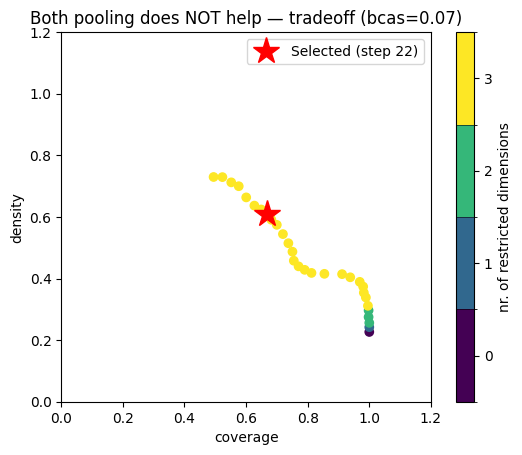


Selected step 22:
coverage      0.668874
density       0.610887
id           22.000000
k           303.000000
mass          0.248000
mean          0.610887
n           496.000000
res_dim       3.000000
Name: 22, dtype: float64

                        box 22                                  
                           min        max      qp value qp value
ccp_r1_inter_bn_min  46.500000  70.000000  1.520451e-07      NaN
distance_ratio        0.335784   0.680048  4.237692e-02  0.03649
ccp_r1_same_bn_min   18.500000  40.000000  2.169935e-01      NaN



In [5]:
delta_both = stove["death_rate_T1_BCAS"].values - both["death_rate_T1_BCAS"].values
y_both_no_help = delta_both <= 0.01
print(f"Both pooling does NOT help: {y_both_no_help.sum()} / {len(y_both_no_help)} ({y_both_no_help.mean():.1%})")

if y_both_no_help.sum() >= 10:
    p_both = prim.Prim(x, y_both_no_help, threshold=0.5)
    box_both = p_both.find_box()
    
    traj = box_both.peeling_trajectory
    print(f"\nPeeling trajectory ({len(traj)} steps):")
    print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))
    
    good = traj[(traj["density"] > 0.60) & (traj["coverage"] > 0.3)]
    if len(good) > 0:
        best_idx = int(good.index[0])
    else:
        good = traj[traj["density"] > 0.40]
        best_idx = int(good.index[0]) if len(good) > 0 else int(len(traj) - 1)
    
    box_both.select(best_idx)
    box_both.show_tradeoff()
    sel = traj.iloc[best_idx]
    plt.plot(sel["coverage"], sel["density"], "r*", markersize=20, zorder=5, label=f"Selected (step {best_idx})")
    plt.legend()
    plt.title("Both pooling does NOT help — tradeoff (bcas=0.07)")
    plt.show()
    
    print(f"\nSelected step {best_idx}:")
    box_both.inspect(best_idx)
else:
    print("Too few cases for PRIM.")

## 2D Scatter — Distance space colored by pooling benefit

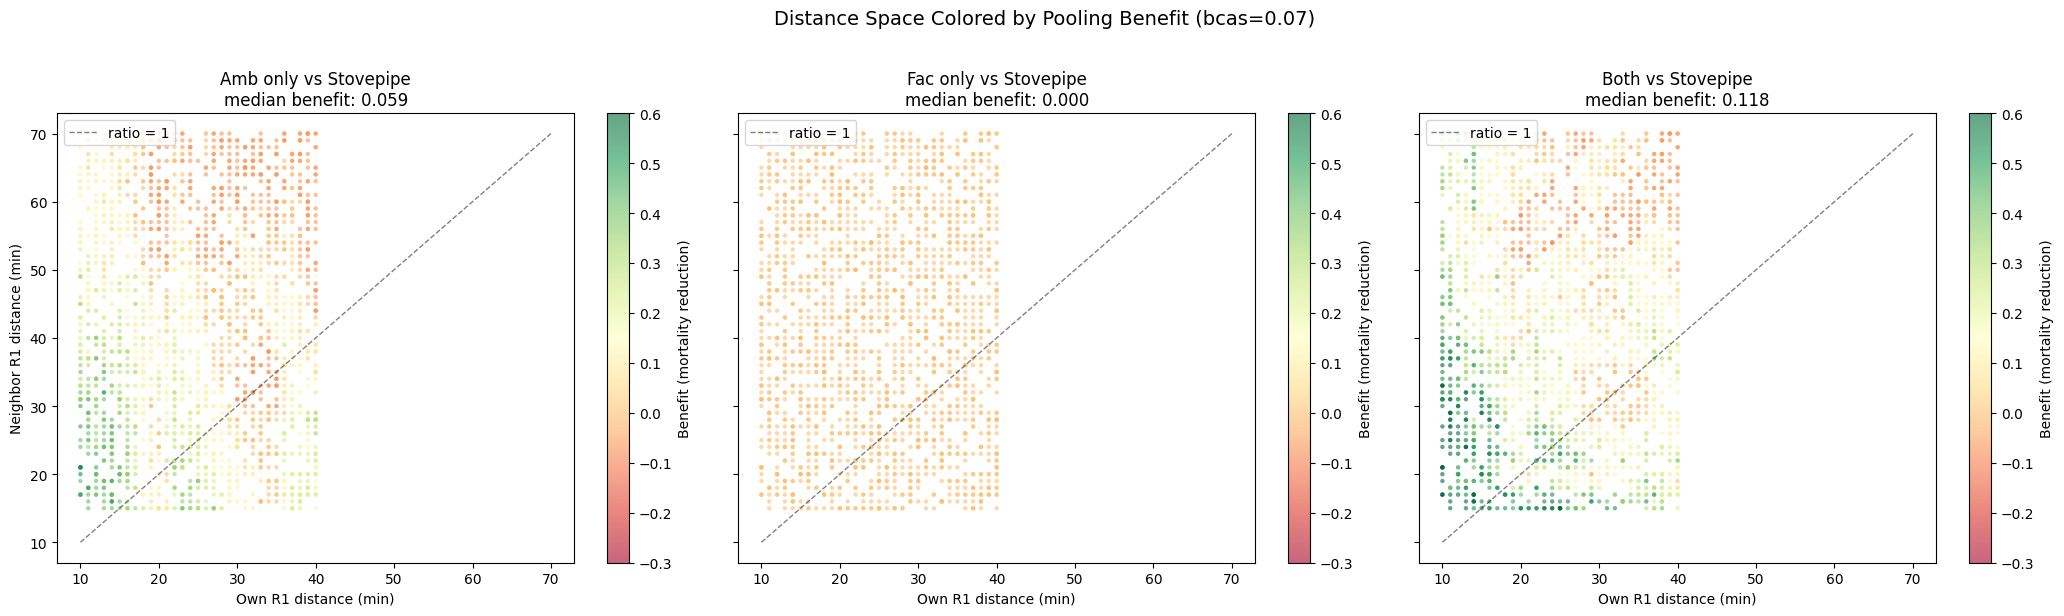

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharey=True, sharex=True)

for ax, (label, policy_df) in zip(axes, comparisons):
    benefit = stove["death_rate_T1_BCAS"].values - policy_df["death_rate_T1_BCAS"].values
    sc = ax.scatter(
        stove["ccp_r1_same_bn_min"].values,
        stove["ccp_r1_inter_bn_min"].values,
        c=benefit, cmap="RdYlGn", vmin=-0.3, vmax=0.6,
        s=10, alpha=0.6, edgecolors="none"
    )
    ax.plot([10, 70], [10, 70], "k--", linewidth=1, alpha=0.5, label="ratio = 1")
    ax.set_xlabel("Own R1 distance (min)")
    if ax == axes[0]:
        ax.set_ylabel("Neighbor R1 distance (min)")
    ax.set_title(f"{label} vs Stovepipe\nmedian benefit: {np.median(benefit):.3f}")
    ax.legend(loc="upper left")
    plt.colorbar(sc, ax=ax, label="Benefit (mortality reduction)")

fig.suptitle("Distance Space Colored by Pooling Benefit (bcas=0.07)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()